In [ ]:
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("PyTorch:", torch.__version__)
print("GPU Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cu130
GPU Available: True
GPU: Tesla T4


In [1]:
from google.colab import files

uploaded = files.upload()

print("Uploaded files:", list(uploaded.keys()))

Saving aksharantar_sampled.zip to aksharantar_sampled.zip
Uploaded files: ['aksharantar_sampled.zip']


In [2]:
import zipfile

zip_path = next(iter(uploaded.keys()))

with zipfile.ZipFile(zip_path, "r") as z:
    print("DATASET FILES:\n")

    for name in z.namelist():
        print(name)

DATASET FILES:

aksharantar_sampled/
aksharantar_sampled/asm/
aksharantar_sampled/asm/asm_test.csv
aksharantar_sampled/asm/asm_train.csv
aksharantar_sampled/asm/asm_valid.csv
aksharantar_sampled/ben/
aksharantar_sampled/ben/ben_test.csv
aksharantar_sampled/ben/ben_train.csv
aksharantar_sampled/ben/ben_valid.csv
aksharantar_sampled/brx/
aksharantar_sampled/brx/brx_test.csv
aksharantar_sampled/brx/brx_train.csv
aksharantar_sampled/brx/brx_valid.csv
aksharantar_sampled/guj/
aksharantar_sampled/guj/guj_test.csv
aksharantar_sampled/guj/guj_train.csv
aksharantar_sampled/guj/guj_valid.csv
aksharantar_sampled/hin/
aksharantar_sampled/hin/hin_test.csv
aksharantar_sampled/hin/hin_train.csv
aksharantar_sampled/hin/hin_valid.csv
aksharantar_sampled/kan/
aksharantar_sampled/kan/kan_test.csv
aksharantar_sampled/kan/kan_train.csv
aksharantar_sampled/kan/kan_valid.csv
aksharantar_sampled/kas/
aksharantar_sampled/kas/kas_test.csv
aksharantar_sampled/kas/kas_train.csv
aksharantar_sampled/kas/kas_valid.c

In [3]:
import os
import zipfile

# Main project directory
PROJECT_DIR = "/content/MTech_AI_ML_Transliteration"

# Dataset directory
DATA_DIR = os.path.join(PROJECT_DIR, "data")

os.makedirs(DATA_DIR, exist_ok=True)

# Extract the uploaded ZIP file
with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(DATA_DIR)

print("Dataset extracted successfully!")

# Hindi dataset location
HINDI_DIR = os.path.join(DATA_DIR, "aksharantar_sampled", "hin")

print("\nHindi dataset files:")

for filename in os.listdir(HINDI_DIR):
    print(filename)

Dataset extracted successfully!

Hindi dataset files:
hin_valid.csv
hin_train.csv
hin_test.csv


In [4]:
train_path = os.path.join(HINDI_DIR, "hin_train.csv")
valid_path = os.path.join(HINDI_DIR, "hin_valid.csv")
test_path = os.path.join(HINDI_DIR, "hin_test.csv")

print("Train file exists:", os.path.exists(train_path))
print("Validation file exists:", os.path.exists(valid_path))
print("Test file exists:", os.path.exists(test_path))

Train file exists: True
Validation file exists: True
Test file exists: True


In [5]:
# Inspect the original training file
with open(train_path, "r", encoding="utf-8") as file:

    print("First five records:\n")

    for i in range(5):
        line = file.readline()

        if not line:
            break

        print(repr(line))

First five records:

'shastragaar,शस्त्रागार\n'
'bindhya,बिन्द्या\n'
'kirankant,किरणकांत\n'
'yagyopaveet,यज्ञोपवीत\n'
'ratania,रटानिया\n'


In [6]:
import pandas as pd

# Load training dataset
train_df = pd.read_csv(
    train_path,
    header=None,
    names=["input", "target"],
    encoding="utf-8"
)

# Load validation dataset
valid_df = pd.read_csv(
    valid_path,
    header=None,
    names=["input", "target"],
    encoding="utf-8"
)

print("Training dataset loaded successfully!")
print("Validation dataset loaded successfully!")

Training dataset loaded successfully!
Validation dataset loaded successfully!


In [7]:
print("TRAINING DATASET")
print("Shape:", train_df.shape)
print("\nFirst 10 records:")
display(train_df.head(10))

print("\nVALIDATION DATASET")
print("Shape:", valid_df.shape)
print("\nFirst 10 records:")
display(valid_df.head(10))

TRAINING DATASET
Shape: (51200, 2)

First 10 records:


,input,target
0,shastragaar,शस्त्रागार
1,bindhya,बिन्द्या
2,kirankant,किरणकांत
3,yagyopaveet,यज्ञोपवीत
4,ratania,रटानिया
5,vaganyache,वागण्याचे
6,deshbharamadhye,देशभरामध्ये
7,sughadpan,सुघड़पन
8,mohiwal,मोहीवाल
9,sarvasangrah,सर्वसंग्रह



VALIDATION DATASET
Shape: (4096, 2)

First 10 records:


,input,target
0,jaisawal,जयसवाल
1,bajai,बजाई
2,sanghthan,संघठन
3,haiwaan,हैवान
4,nilgiri,नीलगिरि
5,drutgrami,द्रुतग्रामी
6,jhadapon,झड़पों
7,nakronda,नकरोंदा
8,eesl,ईईएसएल
9,bachta,बचता


In [8]:
print("Training dataset information:")
train_df.info()

print("\nValidation dataset information:")
valid_df.info()

print("\nMissing values:")
print("Training:", train_df.isnull().sum())
print("Validation:", valid_df.isnull().sum())

print("\nDuplicate rows:")
print("Training:", train_df.duplicated().sum())
print("Validation:", valid_df.duplicated().sum())

Training dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 51200 entries, 0 to 51199
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   input   51200 non-null  object
 1   target  51200 non-null  object
dtypes: object(2)
memory usage: 800.1+ KB

Validation dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4096 entries, 0 to 4095
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   input   4096 non-null   object
 1   target  4096 non-null   object
dtypes: object(2)
memory usage: 64.1+ KB

Missing values:
Training: input     0
target    0
dtype: int64
Validation: input     0
target    0
dtype: int64

Duplicate rows:
Training: 0
Validation: 0


In [9]:
# Calculate character lengths
train_df["input_length"] = train_df["input"].str.len()
train_df["target_length"] = train_df["target"].str.len()

valid_df["input_length"] = valid_df["input"].str.len()
valid_df["target_length"] = valid_df["target"].str.len()

print("Training statistics:")
print("Total words:", len(train_df))
print("Average input length:", train_df["input_length"].mean())
print("Average target length:", train_df["target_length"].mean())
print("Maximum input length:", train_df["input_length"].max())
print("Maximum target length:", train_df["target_length"].max())

Training statistics:
Total words: 51200
Average input length: 8.7069921875
Average target length: 7.79576171875
Maximum input length: 24
Maximum target length: 20


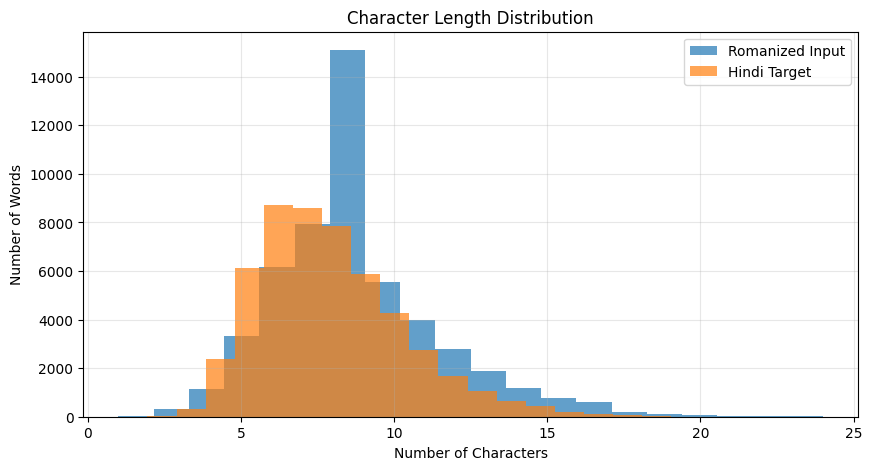

In [11]:
# Import plotting library
import matplotlib.pyplot as plt

# Plot input and target sequence lengths
plt.figure(figsize=(10, 5))

plt.hist(
    train_df["input_length"],
    bins=20,
    alpha=0.7,
    label="Romanized Input"
)

plt.hist(
    train_df["target_length"],
    bins=20,
    alpha=0.7,
    label="Hindi Target"
)

plt.xlabel("Number of Characters")
plt.ylabel("Number of Words")
plt.title("Character Length Distribution")

plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [12]:
# Special tokens
PAD_TOKEN = "<PAD>"
SOS_TOKEN = "<SOS>"
EOS_TOKEN = "<EOS>"
UNK_TOKEN = "<UNK>"

SPECIAL_TOKENS = [
    PAD_TOKEN,
    SOS_TOKEN,
    EOS_TOKEN,
    UNK_TOKEN
]

# Collect unique input characters from training data
input_characters = sorted(
    set("".join(train_df["input"].astype(str)))
)

# Collect unique target characters from training data
target_characters = sorted(
    set("".join(train_df["target"].astype(str)))
)

# Create input vocabulary
input_vocab = SPECIAL_TOKENS + input_characters

# Create target vocabulary
target_vocab = SPECIAL_TOKENS + target_characters

# Create character-to-index mappings
input_char_to_idx = {
    char: idx for idx, char in enumerate(input_vocab)
}

target_char_to_idx = {
    char: idx for idx, char in enumerate(target_vocab)
}

# Create index-to-character mappings
input_idx_to_char = {
    idx: char for char, idx in input_char_to_idx.items()
}

target_idx_to_char = {
    idx: char for char, idx in target_char_to_idx.items()
}

print("Input vocabulary size:", len(input_vocab))
print("Target vocabulary size:", len(target_vocab))

print("\nInput characters:")
print(input_vocab)

print("\nTarget characters:")
print(target_vocab)

Input vocabulary size: 30
Target vocabulary size: 68

Input characters:
['<PAD>', '<SOS>', '<EOS>', '<UNK>', 'a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j', 'k', 'l', 'm', 'n', 'o', 'p', 'q', 'r', 's', 't', 'u', 'v', 'w', 'x', 'y', 'z']

Target characters:
['<PAD>', '<SOS>', '<EOS>', '<UNK>', 'ँ', 'ं', 'ः', 'अ', 'आ', 'इ', 'ई', 'उ', 'ऊ', 'ऋ', 'ए', 'ऐ', 'ऑ', 'ओ', 'औ', 'क', 'ख', 'ग', 'घ', 'ङ', 'च', 'छ', 'ज', 'झ', 'ञ', 'ट', 'ठ', 'ड', 'ढ', 'ण', 'त', 'थ', 'द', 'ध', 'न', 'प', 'फ', 'ब', 'भ', 'म', 'य', 'र', 'ल', 'ळ', 'व', 'श', 'ष', 'स', 'ह', '़', 'ऽ', 'ा', 'ि', 'ी', 'ु', 'ू', 'ृ', 'ॅ', 'े', 'ै', 'ॉ', 'ो', 'ौ', '्']


In [13]:
print("INPUT CHARACTER MAPPING")

for char in input_vocab[:15]:
    print(char, ":", input_char_to_idx[char])

print("\nTARGET CHARACTER MAPPING")

for char in target_vocab[:20]:
    print(char, ":", target_char_to_idx[char])

INPUT CHARACTER MAPPING
<PAD> : 0
<SOS> : 1
<EOS> : 2
<UNK> : 3
a : 4
b : 5
c : 6
d : 7
e : 8
f : 9
g : 10
h : 11
i : 12
j : 13
k : 14

TARGET CHARACTER MAPPING
<PAD> : 0
<SOS> : 1
<EOS> : 2
<UNK> : 3
ँ : 4
ं : 5
ः : 6
अ : 7
आ : 8
इ : 9
ई : 10
उ : 11
ऊ : 12
ऋ : 13
ए : 14
ऐ : 15
ऑ : 16
ओ : 17
औ : 18
क : 19


In [14]:
sample_input = train_df.iloc[0]["input"]
sample_target = train_df.iloc[0]["target"]

input_encoded = [
    input_char_to_idx.get(char, input_char_to_idx[UNK_TOKEN])
    for char in sample_input
]

target_encoded = [
    target_char_to_idx.get(char, target_char_to_idx[UNK_TOKEN])
    for char in sample_target
]

print("Original input:", sample_input)
print("Encoded input:", input_encoded)

print("\nOriginal target:", sample_target)
print("Encoded target:", target_encoded)

Original input: shastragaar
Encoded input: [22, 11, 4, 22, 23, 21, 4, 10, 4, 4, 21]

Original target: शस्त्रागार
Encoded target: [49, 51, 67, 34, 67, 45, 55, 21, 55, 45]
